# Program 31: Customer Behavioral Segmentation via Clustering

**Scenario / Problem Statement**

Segment e-commerce customers using age, browsing time, purchases in the last six months, and total spending with K-Means.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q31_Ecom_Clustering.csv
Dataset shape: (70, 5)
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
Cluster centers (original feature units):


,Customer_ID,Age,Browsing_Minutes_Per_Week,Purchases_Last_6Mo,Total_Spend_USD
0,CUST-001,35,33.6,2,$138.88
1,CUST-002,41,14.1,2,$245.85
2,CUST-003,44,37.4,3,$138.17
3,CUST-004,47,18.9,2,$259.16
4,CUST-005,51,26.5,3,$232.50


,Age,Browsing_Minutes_Per_Week,Purchases_Last_6Mo,Total_Spend_USD
0,31.250000,158.366667,22.333333,2081.730833
1,35.677419,42.422581,4.806452,404.193226
2,57.000000,155.612500,20.125000,2225.277500
3,55.578947,69.352632,7.526316,564.304737


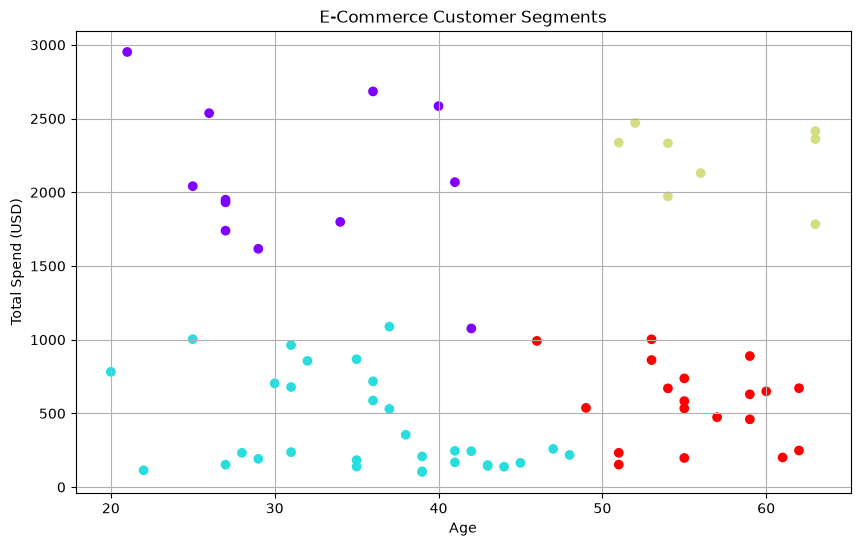

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q31_Ecom_Clustering.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q31_Ecom_Clustering.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

features = ["Age", "Browsing_Minutes_Per_Week", "Purchases_Last_6Mo", "Total_Spend_USD"]
df_raw["Total_Spend_USD"] = pd.to_numeric(df_raw["Total_Spend_USD"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
data = df_raw.dropna(subset=features).copy()
X = data[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
data["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster centers (original feature units):")
display(pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features))

plt.figure(figsize=(10, 6))
plt.scatter(data["Age"], data["Total_Spend_USD"], c=data["Cluster"], cmap="rainbow")
plt.title("E-Commerce Customer Segments")
plt.xlabel("Age")
plt.ylabel("Total Spend (USD)")
plt.grid(True)
plt.show()

## 3. Result

The output above displays the required analysis, model results, or visualization.